In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

In [2]:
file = config.filepath+r'/ELPI/20250707_RIB-PS_1.dat'

In [3]:
with open(file=file, mode='r') as f:
    content=f.read()
    content = content.split('\n')
    physical_channels = np.array(content[12].split('=')[-1].split(';')).astype(float)


physical_data = pd.read_csv(file,sep=';',header=36, usecols=np.append([0],np.arange(2,16,1)), index_col=0)
physical_data.columns=physical_channels[1:]
physical_data.dropna(inplace=True)

physical_data.index = pd.to_datetime(physical_data.index, format='%Y/%m/%d %H:%M:%S.%f')
physical_data.index.names =['DateTime']
physical_data.reset_index(drop=False, inplace=True)

physical_data['Time [s]'] = (physical_data['DateTime'] - physical_data['DateTime'].iloc[0]).dt.total_seconds()


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Grira\\OneDrive - Alstom\\Documents\\Breaq\\Breaq_05-2025\\Echelle reduit-Data\\Python codes\\Code for Reduced scale\\Parcours_PM_PN_PS\\ELPI/ELPI/20250707_RIB-PS_1.dat'

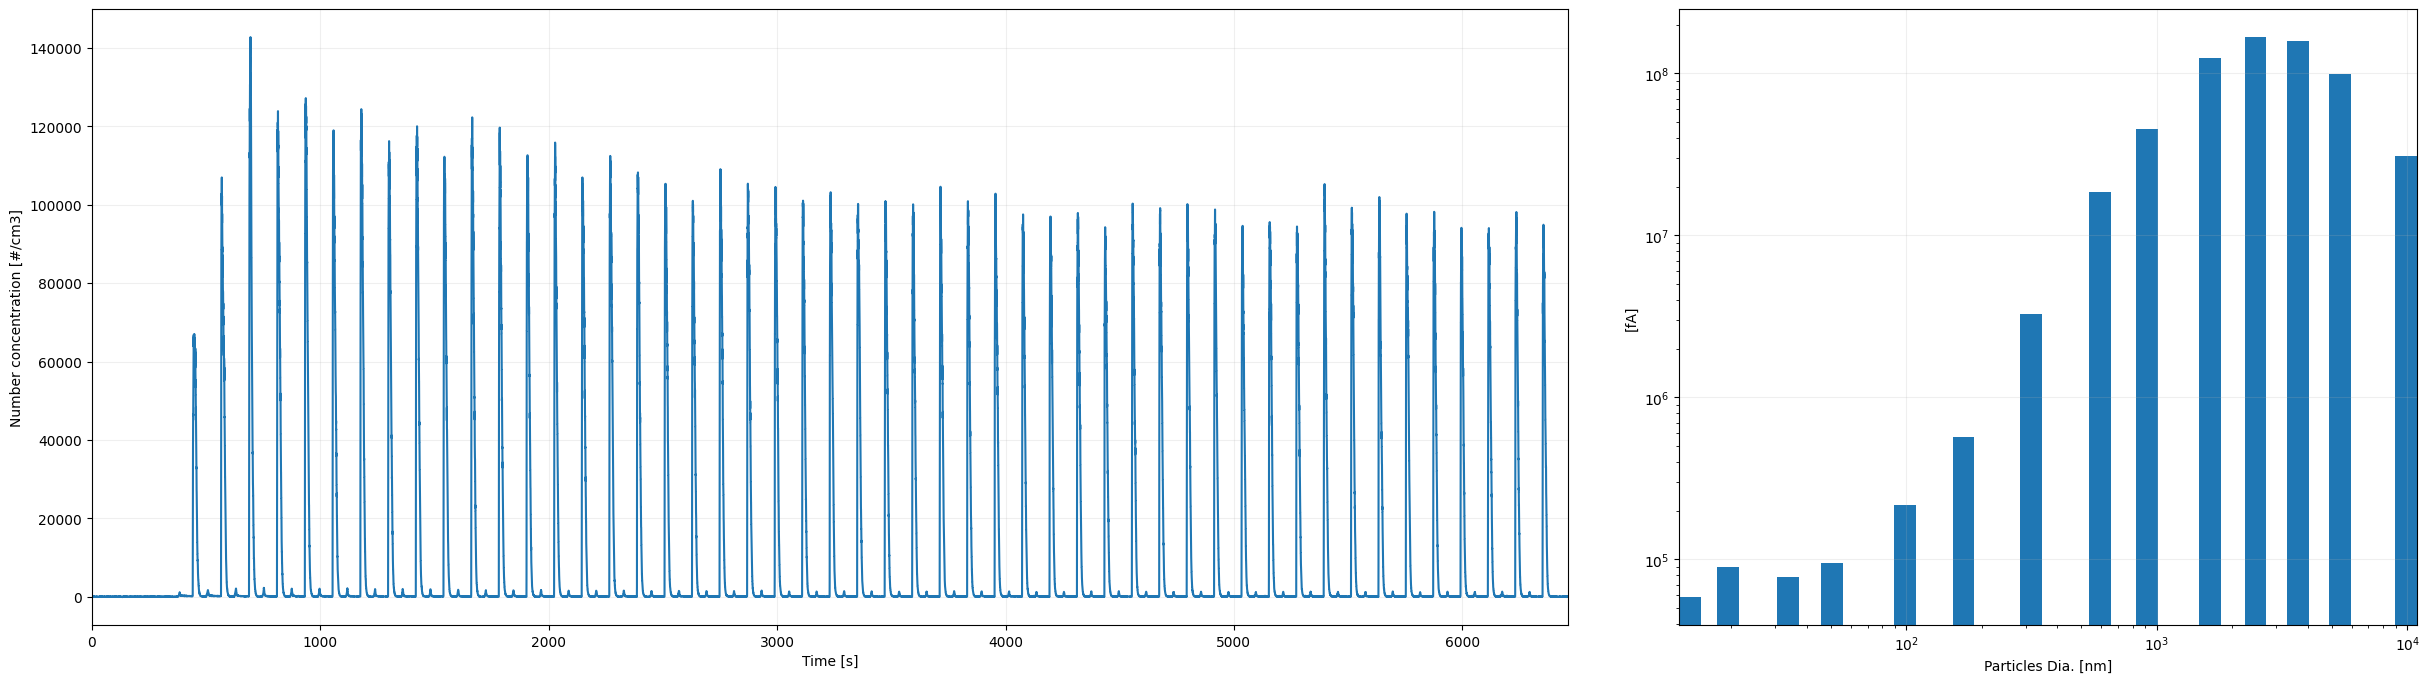

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw={'width_ratios':(1,0.5), 'wspace':0.1})
fig.set_size_inches(w=30, h=8)

ax1.plot(physical_data['Time [s]'], physical_data[physical_data.columns[1:-1]].sum(axis=1))
ax1.set_ylabel('Number concentration [#/cm3]')
ax1.set_xlabel('Time [s]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)

ax2.bar(physical_data.columns[1:-1].astype(float)*1000, height= physical_data[physical_data.columns[1:-1]].sum(axis=0),width=1000* physical_data.columns[1:-1].astype(float)/5 )
ax2.set_xscale('log')
ax2.set_xmargin(0)
ax2.grid(alpha=0.2)
ax2.set_ylabel('[fA]')
ax2.set_xlabel('Particles Dia. [nm]')
ax2.set_yscale('log')

In [ ]:
data = pd.read_csv(config.filepath+r'/ELPI/20250707_RIB-PS_1.dat',sep=';',header=36, usecols=np.append([0],np.arange(38,137,1)), index_col=0)
data.dropna(inplace=True)
data.index = pd.to_datetime(data.index, format='%Y/%m/%d %H:%M:%S.%f')
data.index.names =['DateTime']
data.reset_index(drop=False, inplace=True)
data['Time [s]'] = (data['DateTime'] - data['DateTime'].iloc[0]).dt.total_seconds()

Text(0.5, 0, 'Particles Dia. [nm]')

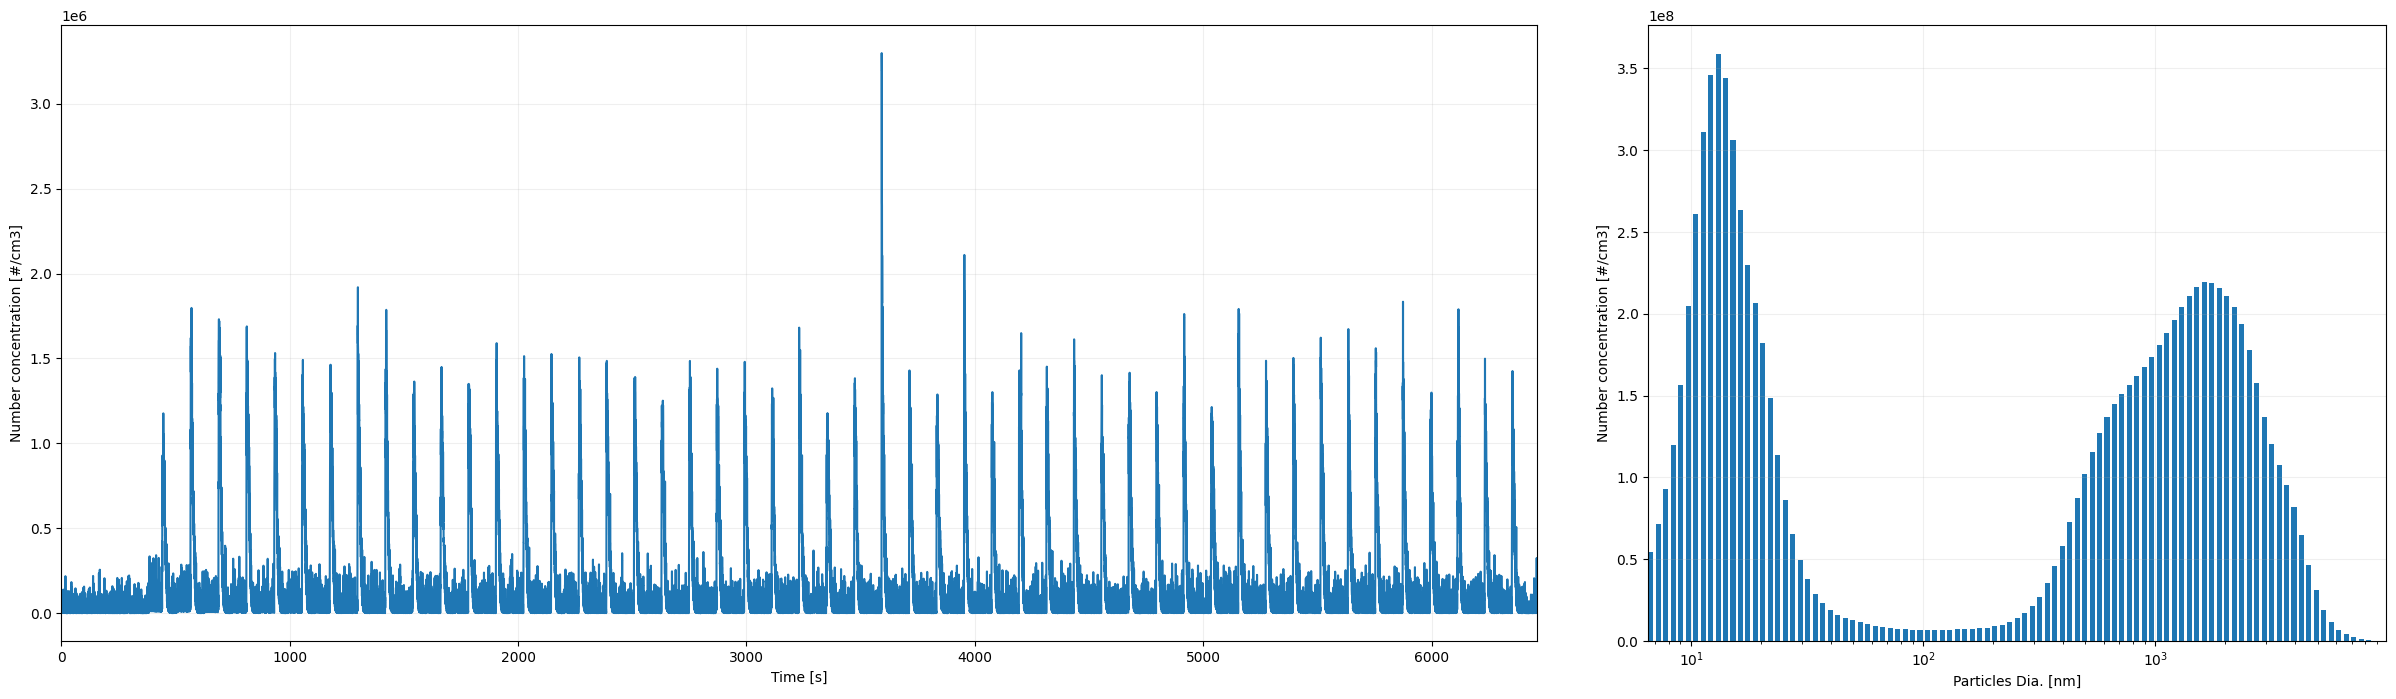

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw={'width_ratios':(1,0.5), 'wspace':0.1})
fig.set_size_inches(w=30, h=8)

ax1.plot(data['Time [s]'], data[data.columns[1:-1]].sum(axis=1))
ax1.set_ylabel('Number concentration [#/cm3]')
ax1.set_xlabel('Time [s]')
ax1.grid(alpha=0.2)
ax1.margins(x=0)

ax2.bar(data.columns[1:-1].astype(float)*1000, height= data[data.columns[1:-1]].sum(axis=0),width=1000* data.columns[1:-1].astype(float)/20 )
ax2.set_xscale('log')
ax2.set_xmargin(0)
ax2.grid(alpha=0.2)
ax2.set_ylabel('Number concentration [#/cm3]')
ax2.set_xlabel('Particles Dia. [nm]')
# ax2.set_yscale('log')